本 notebook 是 [M04.8 ML 研究方法论](../notes/08-research-methodology.qmd) 的实例讲解。

1. 1. 预先固定的基线与配对消融
2. 2. 配对差值、置信区间与独立单位
3. 3. 选择预算与赢家偏差
4. 4. 代理指标与物理目标的排序反转

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import hashlib
import json
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 预先固定的基线与配对消融

在同一训练索引上比较常数、线性与包含交互项的模型；独立生成训练数据，使八次重复的随机性有明确来源。

In [2]:
fixed = np.random.default_rng(2026)
test_x = fixed.normal(size=(1000, 2))
test_y = (
    2 * test_x[:, 0]
    - test_x[:, 1]
    + 1.5 * test_x[:, 0] * test_x[:, 1]
    + fixed.normal(0, 0.3, len(test_x))
)
records = []
for seed in range(8):
    local = np.random.default_rng(seed)
    X = local.normal(size=(120, 2))
    y = 2 * X[:, 0] - X[:, 1] + 1.5 * X[:, 0] * X[:, 1] + local.normal(0, 0.3, len(X))
    designs = {
        "mean": (X, test_x),
        "linear ablation": (X, test_x),
        "interaction": (np.c_[X, X[:, 0] * X[:, 1]], np.c_[test_x, test_x[:, 0] * test_x[:, 1]]),
    }
    for name, (train, test) in designs.items():
        model = DummyRegressor() if name == "mean" else Ridge(alpha=1.0)
        model.fit(train, y)
        records.append(
            {"seed": seed, "model": name, "MAE": mean_absolute_error(test_y, model.predict(test))}
        )
results = pd.DataFrame(records)
paired = results.pivot(index="seed", columns="model", values="MAE")
print(paired)
print("跨训练集均值与标准差:\n", results.groupby("model").MAE.agg(["mean", "std"]))

model  interaction  linear ablation      mean
seed                                         
0         0.250086         1.077873  1.990141
1         0.250820         1.048828  2.026786
2         0.254028         1.034574  1.933324
3         0.250859         1.028438  1.981239
4         0.253316         1.048443  1.991408
5         0.252982         1.031090  1.939387
6         0.262239         1.049841  1.947642
7         0.258952         1.038465  1.955157
跨训练集均值与标准差:
                      mean       std
model                              
interaction      0.254160  0.004293
linear ablation  1.044694  0.015807
mean             1.970635  0.032103


读法：交互项的真实作用由合成机制保证，消融保持相同训练数据、损失和 alpha；八次重复刻画训练数据变化，测试集固定，因此区间不覆盖新测试总体的全部不确定性。

## 2. 配对差值、置信区间与独立单位

对每次重复计算线性消融减去完整模型的误差，再用 t 区间和 bootstrap 表达条件于固定测试集的训练波动。

In [3]:
difference = paired["linear ablation"] - paired["interaction"]
mean = difference.mean()
se = stats.sem(difference)
interval = stats.t.interval(0.95, df=len(difference) - 1, loc=mean, scale=se)
bootstrap = stats.bootstrap(
    (difference.to_numpy(),), np.mean, n_resamples=4000, rng=np.random.default_rng(42), method="BCa"
)
print("平均 MAE 改善:", mean, "t 95% CI:", interval, "bootstrap:", bootstrap.confidence_interval)
print("配对 t 检验:", stats.ttest_rel(paired["linear ablation"], paired["interaction"]))
print("逐次配对差:", difference.to_numpy())

平均 MAE 改善: 0.790533736879482 t 95% CI: (np.float64(0.7763429755926773), np.float64(0.8047244981662868)) bootstrap: ConfidenceInterval(low=np.float64(0.7828582640450636), high=np.float64(0.8074943782944))
配对 t 检验: TtestResult(statistic=np.float64(131.7276225106874), pvalue=np.float64(3.832589227445322e-13), df=np.int64(7))
逐次配对差: [0.82778755 0.79800852 0.78054605 0.77757888 0.79512642 0.77810789
 0.78760204 0.77951254]


读法：正差表示完整模型更好；配对消除共享测试难度的部分波动。八次重复仍少，t 区间依赖差值分布假设，bootstrap 也不能凭空制造独立实验。

## 3. 选择预算与赢家偏差

让所有候选具有相同真实风险，只给验证测量加入噪声，检查候选越多时最佳验证值为何更乐观。

In [4]:
local = np.random.default_rng(42)
trials = 5000
noise = local.normal(0, 0.04, (trials, 200))
rows = []
for budget in [1, 5, 20, 100, 200]:
    selected = noise[:, :budget].argmin(axis=1)
    validation = 0.5 + noise[np.arange(trials), selected]
    independent = 0.5 + local.normal(0, 0.04, trials)
    rows.append([budget, validation.mean(), independent.mean()])
print(
    pd.DataFrame(rows, columns=["candidate budget", "selected validation risk", "independent risk"])
)

   candidate budget  selected validation risk  independent risk
0                 1                  0.499648          0.499496
1                 5                  0.453467          0.500468
2                20                  0.425195          0.499662
3               100                  0.399478          0.499720
4               200                  0.389823          0.500344


读法：更大的选择预算降低了被报告的验证误差，即使没有候选真正更好。公平 benchmark 需说明搜索与人工迭代预算，并保护最终评价。

## 4. 代理指标与物理目标的排序反转

比较两种解析扰动的能量与力误差，再打印一个包含实际数组哈希和版本的复现清单。

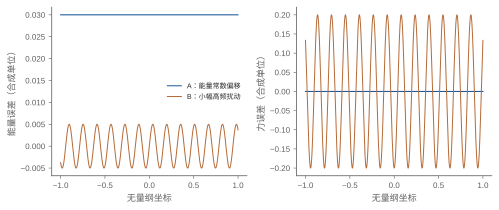

A：能量常数偏移 energy RMSE 0.03 force RMSE 0.0
B：小幅高频扰动 energy RMSE 0.0035575392098536 force RMSE 0.14053563118500148
{
  "chapter": "M04.8",
  "data": "synthetic harmonic coordinate",
  "coordinate_sha256": "e8cb1fc92079804a1cf6538993ea14187d3a9ea4741c467333f884d43ba89c4c",
  "numpy": "2.5.4",
  "sklearn": "1.9.1",
  "split": "fixed test, independent training draws",
  "training_seeds": [
    0,
    1,
    2,
    3,
    4,
    5,
    6,
    7
  ],
  "selection": "three predefined models; no test tuning"
}


In [5]:
x = np.linspace(-1, 1, 1200)
energy = 0.5 * x * x
force = -x
predictions = {
    "A：能量常数偏移": (energy + 0.03, force),
    "B：小幅高频扰动": (energy + 0.005 * np.sin(40 * x), force - 0.2 * np.cos(40 * x)),
}
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for (name, (e, f)), color in zip(predictions.items(), [BLUE, ORANGE], strict=True):
    axes[0].plot(x, e - energy, color=color, label=name, lw=1)
    axes[1].plot(x, f - force, color=color, lw=1)
axes[0].set(xlabel="无量纲坐标", ylabel="能量误差（合成单位）")
axes[1].set(xlabel="无量纲坐标", ylabel="力误差（合成单位）")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

for name, (e, f) in predictions.items():
    print(
        name,
        "energy RMSE",
        np.sqrt(np.mean((e - energy) ** 2)),
        "force RMSE",
        np.sqrt(np.mean((f - force) ** 2)),
    )
manifest = {
    "chapter": "M04.8",
    "data": "synthetic harmonic coordinate",
    "coordinate_sha256": hashlib.sha256(x.tobytes()).hexdigest(),
    "numpy": version("numpy"),
    "sklearn": version("scikit-learn"),
    "split": "fixed test, independent training draws",
    "training_seeds": list(range(8)),
    "selection": "three predefined models; no test tuning",
}
print(json.dumps(manifest, ensure_ascii=False, indent=2))
assert np.sqrt(np.mean((predictions["B：小幅高频扰动"][0] - energy) ** 2)) < 0.03
assert np.max(np.abs(predictions["A：能量常数偏移"][1] - force)) == 0

读法：常数能量偏移不改力，小幅高频能量误差可放大导数误差；清单记录实际数据与协议，但完整复现还需代码版本、依赖锁、配置和原始输出。

## 小结

可靠研究比较的是定义清楚的方法与任务。基线确定参照，消融隔离机制，配对重复限定波动，分层指标连接最终目标，复现记录保留证据来源。每一步都应使主张更具体，而不是只使结果表更大。